<a href="https://colab.research.google.com/github/AnastasyaIrsyad/ProbStat/blob/main/DistribusiProbabilitasPython.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Mengimport Library yang dibutuhkan**

In [3]:
import math
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sympy as sp
from scipy import stats
from scipy.stats import binom, poisson, hypergeom, geom, norm, expon, t, f
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

rng = np.random.default_rng(2026)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
print("Semua library berhasil di-import")

Semua library berhasil di-import


**math — menghitung rumus secara manual**

In [4]:
n, k, p = 5, 2, 0.3
print("C(5,2)            =", math.comb(n, k))
print("5!                =", math.factorial(5))
print("e^-2              =", round(math.exp(-2), 4))
print("P(X=2) manual     =", round(math.comb(n, k) * p**k * (1 - p)**(n - k), 4))

C(5,2)            = 10
5!                = 120
e^-2              = 0.1353
P(X=2) manual     = 0.3087


**statistics — statistik deskriptif & NormalDist**

In [5]:
data_ping = [21, 25, 19, 30, 22, 27, 24, 23]
print("mean     =", statistics.mean(data_ping))
print("variance =", round(statistics.variance(data_ping), 4), "(varians sampel, pembagi n-1)")
print("stdev    =", round(statistics.stdev(data_ping), 4))

nd = statistics.NormalDist(mu=24, sigma=3.5)
print("NormalDist P(X < 30) =", round(nd.cdf(30), 4))
print("NormalDist persentil 95 =", round(nd.inv_cdf(0.95), 4))

mean     = 23.875
variance = 12.125 (varians sampel, pembagi n-1)
stdev    = 3.4821
NormalDist P(X < 30) = 0.9568
NormalDist persentil 95 = 29.757


numpy — pembangkit bilangan acak untuk simulasi

In [6]:
contoh = rng.binomial(n=10, p=0.5, size=8)     # 8 kali lempar 10 koin
print("binomial   :", contoh)
print("poisson    :", rng.poisson(lam=3, size=8))
print("normal     :", rng.normal(loc=0, scale=1, size=4).round(3))
print("choice     :", rng.choice(["OK", "ERROR"], size=6, p=[0.9, 0.1]))

besar = rng.binomial(10, 0.5, size=100_000)
print(f"Mean 100.000 simulasi = {besar.mean():.4f} (teori np = 5) | Var = {besar.var():.4f} (teori npq = 2.5)")

binomial   : [4 6 5 4 4 6 7 4]
poisson    : [6 3 3 0 2 3 6 4]
normal     : [-0.628 -0.826  1.444  0.594]
choice     : ['OK' 'OK' 'OK' 'OK' 'OK' 'OK']
Mean 100.000 simulasi = 4.9911 (teori np = 5) | Var = 2.5046 (teori npq = 2.5)


**pandas — tabel distribusi peluang**

In [7]:
tabel = pd.DataFrame({"x": range(0, 6)})
tabel["P(X=x)"]  = binom.pmf(tabel["x"], 5, 0.3)
tabel["P(X<=x)"] = tabel["P(X=x)"].cumsum()
tabel["x·P(x)"]  = tabel["x"] * tabel["P(X=x)"]
print(tabel.round(4).to_string(index=False))
print("\nTotal peluang =", round(tabel["P(X=x)"].sum(), 4), "| E(X) = Σ x·P(x) =", round(tabel["x·P(x)"].sum(), 4))

 x  P(X=x)  P(X<=x)  x·P(x)
 0  0.1681   0.1681  0.0000
 1  0.3601   0.5282  0.3601
 2  0.3087   0.8369  0.6174
 3  0.1323   0.9692  0.3969
 4  0.0283   0.9976  0.1134
 5  0.0024   1.0000  0.0121

Total peluang = 1.0 | E(X) = Σ x·P(x) = 1.5


**scipy.stats — objek distribusi**

In [8]:
X = binom(5, 0.3)
print("pmf(2)      =", round(X.pmf(2), 4))
print("cdf(2)      =", round(X.cdf(2), 4))
print("sf(2)       =", round(X.sf(2), 4))
print("ppf(0.9)    =", X.ppf(0.9))
print("mean, var   =", X.mean(), round(X.var(), 4))
print("mvsk        =", [round(float(v), 4) for v in X.stats(moments="mvsk")])
print("interval 95%=", X.interval(0.95))
print("rvs(5)      =", X.rvs(size=5, random_state=rng))

pmf(2)      = 0.3087
cdf(2)      = 0.8369
sf(2)       = 0.1631
ppf(0.9)    = 3.0
mean, var   = 1.5 1.05
mvsk        = [1.5, 1.05, 0.3904, -0.2476]
interval 95%= (np.float64(0.0), np.float64(4.0))
rvs(5)      = [0 1 1 2 1]


**sympy — menurunkan nilai harapan secara simbolik**

In [9]:
# Distribusi eksponensial f(x) = λ e^(-λx): buktikan E(X) = 1/λ dan Var(X) = 1/λ²
x, lam = sp.symbols("x lambda", positive=True)
fx = lam * sp.exp(-lam * x)
EX  = sp.integrate(x * fx, (x, 0, sp.oo))
EX2 = sp.integrate(x**2 * fx, (x, 0, sp.oo))
print("∫ f(x) dx =", sp.integrate(fx, (x, 0, sp.oo)))
print("E(X)      =", sp.simplify(EX))
print("Var(X)    =", sp.simplify(EX2 - EX**2))

∫ f(x) dx = 1
E(X)      = 1/lambda
Var(X)    = lambda**(-2)


**matplotlib & seaborn — visualisasi**

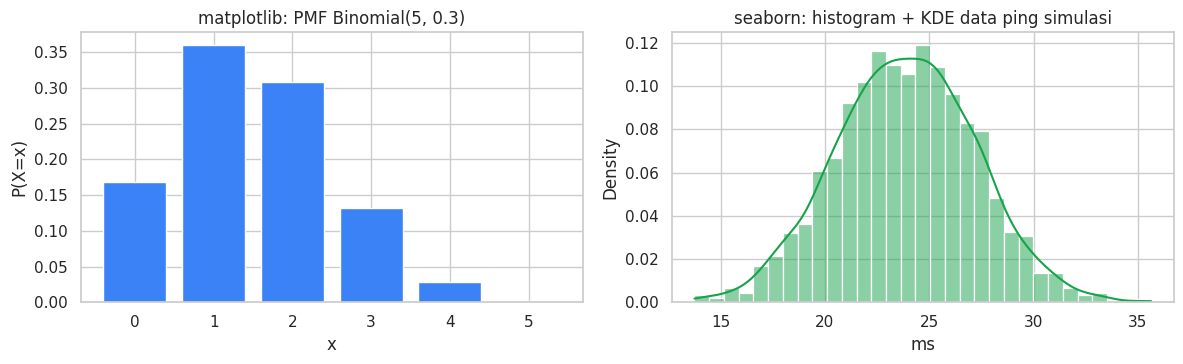

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
xs = np.arange(0, 6)
ax[0].bar(xs, binom.pmf(xs, 5, 0.3), color="#3b82f6")
ax[0].set_title("matplotlib: PMF Binomial(5, 0.3)"); ax[0].set_xlabel("x"); ax[0].set_ylabel("P(X=x)")

sns.histplot(rng.normal(24, 3.5, 2000), kde=True, stat="density", ax=ax[1], color="#16a34a")
ax[1].set_title("seaborn: histogram + KDE data ping simulasi"); ax[1].set_xlabel("ms")
plt.tight_layout(); plt.show()

**statsmodels — pemodelan statistik**

In [11]:
# Contoh kecil: apakah rata-rata ping 3 ISP berbeda? (tabel ANOVA otomatis)
df_isp = pd.DataFrame({
    "isp":  ["A"]*4 + ["B"]*4 + ["C"]*4,
    "ping": [20, 22, 21, 23,  25, 27, 26, 24,  21, 20, 22, 21],
})
model = ols("ping ~ C(isp)", data=df_isp).fit()
print(sm.stats.anova_lm(model, typ=1).round(4))

           df   sum_sq  mean_sq      F  PR(>F)
C(isp)    2.0  48.6667  24.3333  18.25  0.0007
Residual  9.0  12.0000   1.3333    NaN     NaN


## Implementasi pada Distribusi Probabilitas

## A. DISTRIBUSI DISKRIT
Variabel acak **diskrit** hanya bisa bernilai bilangan cacah (0, 1, 2, …). Peluangnya dihitung dengan **PMF** P(X = x), dan jumlah semua peluang = 1.

## 1. Distribusi Binomial — Packet Loss pada Jaringan

**Konsep:** X = jumlah sukses dalam **n percobaan tetap**, tiap percobaan hanya 2 hasil, peluang sukses **p tetap**, dan percobaan **saling independen**.

P(X = x) = C(n, x) · pˣ · (1 − p)ⁿ⁻ˣ  E(X) = np  Var(X) = np(1 − p)

**Soal**
Sebuah router mengirim **20 paket** data. Setiap paket punya peluang **hilang 5%**, dan hilangnya satu paket tidak memengaruhi paket lain. Jika **3 paket atau lebih** hilang, video call akan patah-patah.

a. P(tidak ada paket hilang)

b. P(tepat 1 paket hilang)

c. P(paling banyak 2 paket hilang)

d. P(video patah-patah) = P(X ≥ 3)

e. Nilai harapan, varians, simpangan baku

f. Simulasi 10.000 kali pengiriman, bandingkan dengan teori

**Cek syarat binomial:** n = 20 tetap ✔ · 2 hasil (hilang/sampai) ✔ · p = 0.05 tetap ✔ · paket independen ✔

**Hitung manual**
- a. P(X = 0) = C(20,0)(0.05)⁰(0.95)²⁰ = 0.95²⁰ = **0.3585**
- b. P(X = 1) = C(20,1)(0.05)¹(0.95)¹⁹ = 20 × 0.05 × 0.3774 = **0.3774**
- c. P(X = 2) = C(20,2)(0.05)²(0.95)¹⁸ = 190 × 0.0025 × 0.3972 = 0.1887 → P(X ≤ 2) = 0.3585 + 0.3774 + 0.1887 = **0.9245**
- d. P(X ≥ 3) = 1 − 0.9245 = **0.0755**
- e. E(X) = 20 × 0.05 = **1**, Var = 20 × 0.05 × 0.95 = **0.95**, σ = √0.95 = **0.9747**

In [12]:
n, p = 20, 0.05
X = binom(n, p)

# Rumus manual dengan math sebagai pembanding
manual = {x: math.comb(n, x) * p**x * (1 - p)**(n - x) for x in range(3)}

print("=== Peluang (scipy vs manual) ===")
print(f"a. P(X = 0)  = pmf(0) = {X.pmf(0):.4f}   manual = {manual[0]:.4f}")
print(f"b. P(X = 1)  = pmf(1) = {X.pmf(1):.4f}   manual = {manual[1]:.4f}")
print(f"c. P(X ≤ 2)  = cdf(2) = {X.cdf(2):.4f}   manual = {sum(manual.values()):.4f}")
print(f"d. P(X ≥ 3)  = sf(2)  = {X.sf(2):.4f}   manual = {1 - sum(manual.values()):.4f}")

m, v, s, k = X.stats(moments="mvsk")
print("\n=== Nilai harapan & varians ===")
print(f"e. E(X) = {m:.4f} | Var(X) = {v:.4f} | σ = {X.std():.4f} | skewness = {s:.4f}")

=== Peluang (scipy vs manual) ===
a. P(X = 0)  = pmf(0) = 0.3585   manual = 0.3585
b. P(X = 1)  = pmf(1) = 0.3774   manual = 0.3774
c. P(X ≤ 2)  = cdf(2) = 0.9245   manual = 0.9245
d. P(X ≥ 3)  = sf(2)  = 0.0755   manual = 0.0755

=== Nilai harapan & varians ===
e. E(X) = 1.0000 | Var(X) = 0.9500 | σ = 0.9747 | skewness = 0.9234


 x  Teori (pmf)  Simulasi (rvs)
 0       0.3585          0.3527
 1       0.3774          0.3883
 2       0.1887          0.1850
 3       0.0596          0.0604
 4       0.0133          0.0107
 5       0.0022          0.0026
 6       0.0003          0.0003

Mean simulasi = 0.9971 | teori = 1.0000
Var  simulasi = 0.9247 | teori = 0.9500
P(X ≥ 3) simulasi = 0.0740 | teori = 0.0755


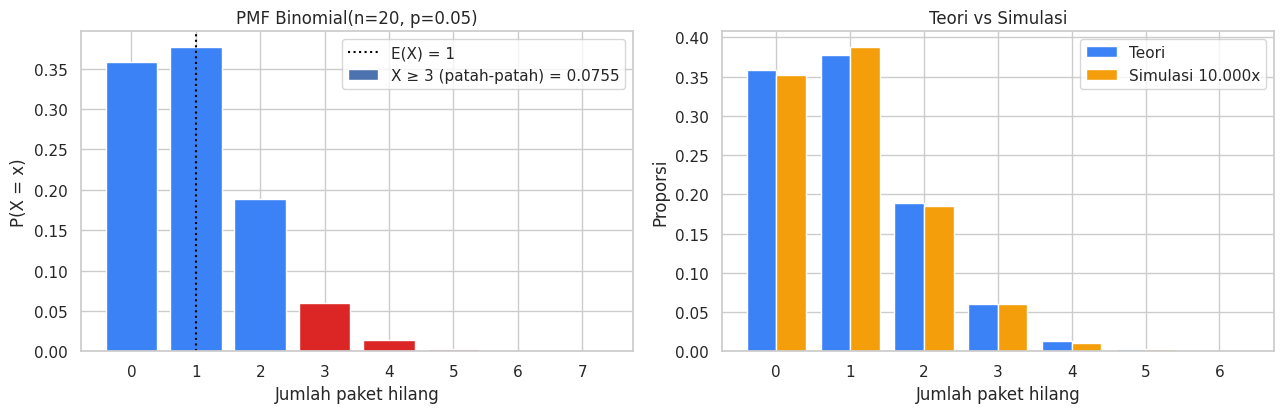

In [13]:
# f. Simulasi 10.000 kali pengiriman 20 paket
sim = X.rvs(size=10_000, random_state=rng)

banding = pd.DataFrame({"x": range(7)})
banding["Teori (pmf)"]    = X.pmf(banding["x"])
banding["Simulasi (rvs)"] = [(sim == k).mean() for k in banding["x"]]
print(banding.round(4).to_string(index=False))
print(f"\nMean simulasi = {sim.mean():.4f} | teori = {X.mean():.4f}")
print(f"Var  simulasi = {sim.var():.4f} | teori = {X.var():.4f}")
print(f"P(X ≥ 3) simulasi = {(sim >= 3).mean():.4f} | teori = {X.sf(2):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
xs = np.arange(0, 8)
ax[0].bar(xs, X.pmf(xs), color=["#dc2626" if x >= 3 else "#3b82f6" for x in xs])
ax[0].axvline(X.mean(), ls=":", color="black", label="E(X) = 1")
ax[0].bar([], [], color="#dc2626", label=f"X ≥ 3 (patah-patah) = {X.sf(2):.4f}")
ax[0].set(title="PMF Binomial(n=20, p=0.05)", xlabel="Jumlah paket hilang", ylabel="P(X = x)"); ax[0].legend()

w = 0.4
ax[1].bar(banding["x"] - w/2, banding["Teori (pmf)"], w, label="Teori", color="#3b82f6")
ax[1].bar(banding["x"] + w/2, banding["Simulasi (rvs)"], w, label="Simulasi 10.000x", color="#f59e0b")
ax[1].set(title="Teori vs Simulasi", xlabel="Jumlah paket hilang", ylabel="Proporsi"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2. Distribusi Poisson — Request ke Server per Detik

**Konsep:** X = jumlah kejadian dalam **satu selang waktu/ruang**, kejadian terjadi acak dan independen dengan **rata-rata λ** per selang.

P(X = x) = e^(−λ) · λˣ / x!  E(X) = λ  Var(X) = λ

**Soal**
Sebuah API menerima **rata-rata 4 request per detik**. Server hanya mampu memproses **maksimal 8 request per detik**; lebih dari itu server *overload*.

a. P(tidak ada request dalam 1 detik)

b. P(tepat 4 request)

c. P(overload) = P(X > 8)

d. Kapasitas minimal agar server tidak overload pada **99%** detik (`ppf`)

e. Buktikan secara simbolik bahwa E(X) = Var(X) = λ (`sympy`)

f. Simulasi 1 jam (3.600 detik) dengan `numpy`

**Hitung manual**
- a. P(X = 0) = e⁻⁴ = **0.0183**
- b. P(X = 4) = e⁻⁴ · 4⁴ / 4! = 0.0183 × 256 / 24 = **0.1954**
- c. P(X > 8) = 1 − Σ₀⁸ P(X = x) = 1 − 0.9786 = **0.0214**
- E(X) = Var(X) = **4**, σ = √4 = **2**

In [14]:
lam = 4
X = poisson(lam)

manual_4 = math.exp(-lam) * lam**4 / math.factorial(4)
print("=== Peluang ===")
print(f"a. P(X = 0) = pmf(0) = {X.pmf(0):.4f}")
print(f"b. P(X = 4) = pmf(4) = {X.pmf(4):.4f}   manual = {manual_4:.4f}")
print(f"c. P(X > 8) = sf(8)  = {X.sf(8):.4f}")

kap = X.ppf(0.99)
print(f"d. ppf(0.99) = {kap:.0f} request/detik   (cek cdf({kap:.0f}) = {X.cdf(kap):.4f}, cdf({kap-1:.0f}) = {X.cdf(kap-1):.4f})")
print(f"\nE(X) = {X.mean():.0f} | Var(X) = {X.var():.0f} | σ = {X.std():.0f}")

=== Peluang ===
a. P(X = 0) = pmf(0) = 0.0183
b. P(X = 4) = pmf(4) = 0.1954   manual = 0.1954
c. P(X > 8) = sf(8)  = 0.0214
d. ppf(0.99) = 9 request/detik   (cek cdf(9) = 0.9919, cdf(8) = 0.9786)

E(X) = 4 | Var(X) = 4 | σ = 2


In [15]:
# e. Bukti simbolik dengan sympy: E(X) = Σ x·P(x), Var(X) = E(X²) − E(X)²
xk = sp.symbols("x", integer=True, nonnegative=True)
L = sp.symbols("lambda", positive=True)
pmf_sym = sp.exp(-L) * L**xk / sp.factorial(xk)

total = sp.simplify(sp.summation(pmf_sym, (xk, 0, sp.oo)))
EX    = sp.simplify(sp.summation(xk * pmf_sym, (xk, 0, sp.oo)))
EX2   = sp.simplify(sp.summation(xk**2 * pmf_sym, (xk, 0, sp.oo)))
print("Σ P(x)  =", total)
print("E(X)    =", EX)
print("Var(X)  =", sp.simplify(EX2 - EX**2))

Σ P(x)  = 1
E(X)    = lambda
Var(X)  = lambda


Mean simulasi = 3.9328 | Var simulasi = 3.9638  (Poisson: mean ≈ var)
Detik overload: simulasi = 74 detik | teori = 76.9 detik


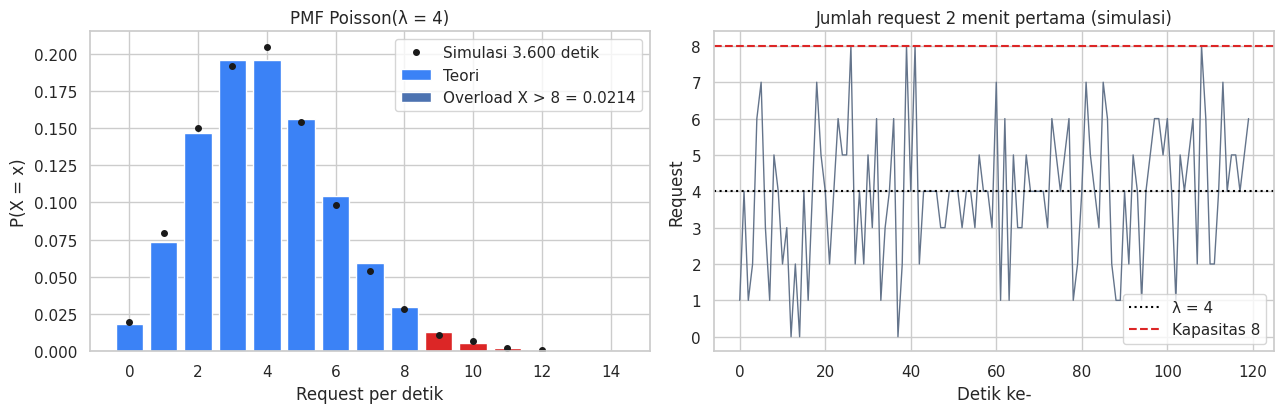

In [16]:
# f. Simulasi 3.600 detik dengan numpy
sim = rng.poisson(lam=lam, size=3600)
print(f"Mean simulasi = {sim.mean():.4f} | Var simulasi = {sim.var():.4f}  (Poisson: mean ≈ var)")
print(f"Detik overload: simulasi = {(sim > 8).sum()} detik | teori = {X.sf(8) * 3600:.1f} detik")

frek = pd.Series(sim).value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
xs = np.arange(0, 15)
ax[0].bar(xs, X.pmf(xs), color=["#dc2626" if x > 8 else "#3b82f6" for x in xs], label="Teori")
ax[0].plot(frek.index, frek.values, "ko", ms=4, label="Simulasi 3.600 detik")
ax[0].bar([], [], color="#dc2626", label=f"Overload X > 8 = {X.sf(8):.4f}")
ax[0].set(title="PMF Poisson(λ = 4)", xlabel="Request per detik", ylabel="P(X = x)"); ax[0].legend()

ax[1].plot(sim[:120], color="#64748b", lw=1)
ax[1].axhline(lam, ls=":", color="black", label="λ = 4")
ax[1].axhline(8, ls="--", color="#dc2626", label="Kapasitas 8")
ax[1].set(title="Jumlah request 2 menit pertama (simulasi)", xlabel="Detik ke-", ylabel="Request"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Distribusi Hipergeometrik — File Korup di Folder Backup

**Konsep:** mengambil **n item tanpa pengembalian** dari populasi **N** yang berisi **k** item "sukses". X = jumlah sukses di sampel. Karena tanpa pengembalian, peluang berubah tiap pengambilan (bukan binomial).

P(X = x) = C(k, x) · C(N − k, n − x) / C(N, n)  E(X) = n·k/N  Var(X) = n·(k/N)·(1 − k/N)·(N − n)/(N − 1)

**Soal**
Folder backup berisi **50 file**, **8 di antaranya korup**. Tim IT mengambil **5 file secara acak** (tanpa pengembalian) untuk diperiksa.

a. Tabel P(X = x) untuk x = 0–5

b. P(minimal 1 file korup terdeteksi)

c. E(X), Var(X), σ

d. Bandingkan dengan binomial (seolah-olah dengan pengembalian, p = 8/50)

e. Simulasi pengambilan tanpa pengembalian 50.000 kali

**Hitung manual**
- P(X = 0) = C(8,0)·C(42,5)/C(50,5) = 850.668 / 2.118.760 = **0.4015**
- P(X ≥ 1) = 1 − 0.4015 = **0.5985**
- E(X) = 5 × 8/50 = **0.8**
- Var(X) = 5 × 0.16 × 0.84 × (45/49) = **0.6171**, σ = **0.7856**


In [17]:
N_pop, k_korup, n_ambil = 50, 8, 5
H = hypergeom(M=N_pop, n=k_korup, N=n_ambil)
B = binom(n_ambil, k_korup / N_pop)               # pembanding: dengan pengembalian

manual_0 = math.comb(8, 0) * math.comb(42, 5) / math.comb(50, 5)

tabel = pd.DataFrame({"x": range(6)})
tabel["Hipergeometrik"] = H.pmf(tabel["x"])
tabel["Binomial p=0.16"] = B.pmf(tabel["x"])
tabel["Selisih"] = tabel["Hipergeometrik"] - tabel["Binomial p=0.16"]
print("a. Tabel distribusi")
print(tabel.round(4).to_string(index=False))

print(f"\nb. P(X ≥ 1) = sf(0) = {H.sf(0):.4f}   (manual 1 - {manual_0:.4f} = {1 - manual_0:.4f})")
print(f"c. E(X) = {H.mean():.4f} | Var(X) = {H.var():.4f} | σ = {H.std():.4f}")
print(f"d. Binomial: E(X) = {B.mean():.4f} | Var(X) = {B.var():.4f} | P(X ≥ 1) = {B.sf(0):.4f}")

a. Tabel distribusi
 x  Hipergeometrik  Binomial p=0.16  Selisih
 0          0.4015           0.4182  -0.0167
 1          0.4226           0.3983   0.0243
 2          0.1517           0.1517  -0.0000
 3          0.0228           0.0289  -0.0061
 4          0.0014           0.0028  -0.0014
 5          0.0000           0.0001  -0.0001

b. P(X ≥ 1) = sf(0) = 0.5985   (manual 1 - 0.4015 = 0.5985)
c. E(X) = 0.8000 | Var(X) = 0.6171 | σ = 0.7856
d. Binomial: E(X) = 0.8000 | Var(X) = 0.6720 | P(X ≥ 1) = 0.5818


Tanpa pengembalian : mean = 0.8013, var = 0.6187, P(X≥1) = 0.5998
Dengan pengembalian: mean = 0.8007, var = 0.6721, P(X≥1) = 0.5825


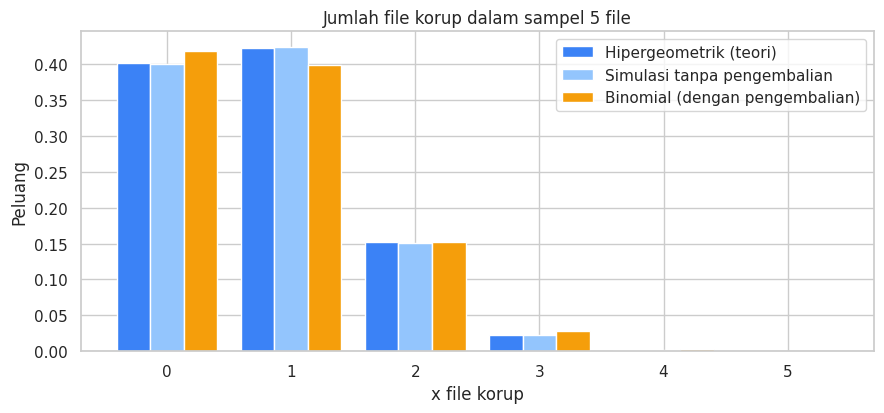

In [18]:
# e. Simulasi langsung: 1 = file korup, 0 = normal
folder = np.array([1] * k_korup + [0] * (N_pop - k_korup))
ulang = 50_000
tanpa  = np.array([rng.choice(folder, size=n_ambil, replace=False).sum() for _ in range(ulang)])
dengan = rng.choice(folder, size=(ulang, n_ambil), replace=True).sum(axis=1)

print(f"Tanpa pengembalian : mean = {tanpa.mean():.4f}, var = {tanpa.var():.4f}, P(X≥1) = {(tanpa >= 1).mean():.4f}")
print(f"Dengan pengembalian: mean = {dengan.mean():.4f}, var = {dengan.var():.4f}, P(X≥1) = {(dengan >= 1).mean():.4f}")

fig, ax = plt.subplots(figsize=(9, 4.3))
w = 0.27; xs = np.arange(6)
ax.bar(xs - w, H.pmf(xs), w, label="Hipergeometrik (teori)", color="#3b82f6")
ax.bar(xs, [(tanpa == x).mean() for x in xs], w, label="Simulasi tanpa pengembalian", color="#93c5fd")
ax.bar(xs + w, B.pmf(xs), w, label="Binomial (dengan pengembalian)", color="#f59e0b")
ax.set(title="Jumlah file korup dalam sampel 5 file", xlabel="x file korup", ylabel="Peluang"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Distribusi Geometrik — Percobaan Koneksi ke Server

**Konsep:** X = **nomor percobaan** saat **sukses pertama** terjadi. Tiap percobaan independen dengan peluang sukses p tetap. (Di scipy.stats.geom, X dimulai dari 1.)

P(X = x) = (1 − p)ˣ⁻¹ · p  P(X ≤ x) = 1 − (1 − p)ˣ  E(X) = 1/p  Var(X) = (1 − p)/p²

**Soal**
Aplikasi mobile mencoba terhubung ke server yang sedang sibuk. Setiap percobaan berhasil dengan peluang **0.25** dan saling bebas. Aplikasi terus mencoba sampai berhasil.

a. P(berhasil tepat pada percobaan ke-3)

b. P(berhasil dalam ≤ 4 percobaan)

c. P(butuh lebih dari 6 percobaan)

d. E(X), Var(X), σ

e. Batas *retry* minimal agar **90%** pengguna sudah terhubung

f. Simulasi 20.000 pengguna dan cek sifat *memoryless*: P(X > 6 | X > 3) = P(X > 3)

**Hitung manual**
- a. P(X = 3) = 0.75² × 0.25 = **0.1406**
- b. P(X ≤ 4) = 1 − 0.75⁴ = **0.6836**
- c. P(X > 6) = 0.75⁶ = **0.1780**
- d. E(X) = 1/0.25 = **4**, Var = 0.75/0.0625 = **12**, σ = **3.4641**
- e. 1 − 0.75ˣ ≥ 0.9 → x ≥ ln(0.1)/ln(0.75) = 8.0039 → **x = 9**

In [19]:
p = 0.25
X = geom(p)

print(f"a. P(X = 3)  = pmf(3) = {X.pmf(3):.4f}   manual = {(1 - p)**2 * p:.4f}")
print(f"b. P(X ≤ 4)  = cdf(4) = {X.cdf(4):.4f}   manual = {1 - (1 - p)**4:.4f}")
print(f"c. P(X > 6)  = sf(6)  = {X.sf(6):.4f}   manual = {(1 - p)**6:.4f}")
print(f"d. E(X) = {X.mean():.0f} | Var(X) = {X.var():.0f} | σ = {X.std():.4f}")
print(f"e. ppf(0.90) = {X.ppf(0.90):.0f} percobaan   (manual ln(0.1)/ln(0.75) = {math.log(0.1)/math.log(0.75):.4f})")

a. P(X = 3)  = pmf(3) = 0.1406   manual = 0.1406
b. P(X ≤ 4)  = cdf(4) = 0.6836   manual = 0.6836
c. P(X > 6)  = sf(6)  = 0.1780   manual = 0.1780
d. E(X) = 4 | Var(X) = 12 | σ = 3.4641
e. ppf(0.90) = 9 percobaan   (manual ln(0.1)/ln(0.75) = 8.0039)


Mean simulasi = 3.9984 (teori 4) | Var simulasi = 11.7894 (teori 12)
Pengguna yang butuh > 6 percobaan: 0.1777 (teori 0.1780)

Memoryless: P(X > 6 | X > 3) simulasi = 0.4180 | P(X > 3) teori = 0.4219


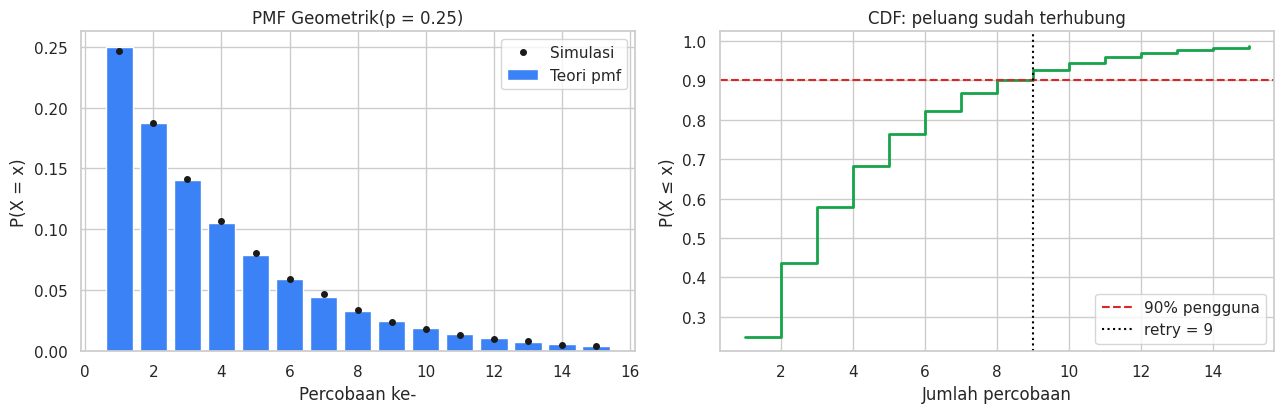

In [20]:
# f. Simulasi 20.000 pengguna dengan numpy
sim = rng.geometric(p, size=20_000)
print(f"Mean simulasi = {sim.mean():.4f} (teori 4) | Var simulasi = {sim.var():.4f} (teori 12)")
print(f"Pengguna yang butuh > 6 percobaan: {(sim > 6).mean():.4f} (teori {X.sf(6):.4f})")

# Sifat memoryless
p_bersyarat = (sim > 6).sum() / (sim > 3).sum()
print(f"\nMemoryless: P(X > 6 | X > 3) simulasi = {p_bersyarat:.4f} | P(X > 3) teori = {X.sf(3):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
xs = np.arange(1, 16)
ax[0].bar(xs, X.pmf(xs), color="#3b82f6", label="Teori pmf")
ax[0].plot(xs, [(sim == x).mean() for x in xs], "ko", ms=4, label="Simulasi")
ax[0].set(title="PMF Geometrik(p = 0.25)", xlabel="Percobaan ke-", ylabel="P(X = x)"); ax[0].legend()

ax[1].step(xs, X.cdf(xs), where="post", color="#16a34a", lw=2)
ax[1].axhline(0.9, ls="--", color="#dc2626", label="90% pengguna")
ax[1].axvline(X.ppf(0.9), ls=":", color="black", label=f"retry = {X.ppf(0.9):.0f}")
ax[1].set(title="CDF: peluang sudah terhubung", xlabel="Jumlah percobaan", ylabel="P(X ≤ x)"); ax[1].legend()
plt.tight_layout(); plt.show()

## B. DISTRIBUSI KONTINU
Variabel acak **kontinu** bisa bernilai berapa saja dalam suatu rentang. Peluang dihitung sebagai **luas di bawah kurva PDF**, sehingga **P(X = x) = 0** dan yang dihitung selalu peluang rentang, misalnya P(a < X < b) = F(b) − F(a).

## 5. Distribusi Normal — Waktu Respons API

**Konsep:** kurva lonceng simetris dengan rata-rata μ dan simpangan baku σ. Nilai diubah ke skala baku dengan **Z = (X − μ)/σ**.

E(X) = μ  Var(X) = σ²  Aturan 68–95–99.7: ±68.27% data di μ ± 1σ, ±95.45% di μ ± 2σ, ±99.73% di μ ± 3σ

**Soal**
Waktu respons endpoint API berdistribusi normal dengan **μ = 200 ms** dan **σ = 40 ms**. Respons di atas **300 ms** dianggap *timeout*.

a. P(respons < 250 ms)

b. P(timeout) = P(X > 300)

c. P(150 < X < 250)

d. Latency **p95** dan **p99** (dipakai untuk SLO)

e. Bandingkan hasil scipy.stats.norm dengan statistics.NormalDist

f. Simulasi 100.000 request: cek aturan 68–95–99.7 dan taksir ulang μ, σ dengan norm.fit

**Hitung manual**
- a. Z = (250 − 200)/40 = 1.25 → Φ(1.25) = **0.8944**
- b. Z = (300 − 200)/40 = 2.5 → 1 − Φ(2.5) = 1 − 0.9938 = **0.0062**
- c. Z = −1.25 s/d 1.25 → 0.8944 − 0.1056 = **0.7887**
- d. p95 = 200 + 1.645 × 40 = **265.8 ms**; p99 = 200 + 2.326 × 40 = **293.1 ms**

In [21]:
mu, sigma = 200, 40
X = norm(loc=mu, scale=sigma)
nd = statistics.NormalDist(mu, sigma)

print("=== Peluang ===")
print(f"a. P(X < 250)       = cdf(250)            = {X.cdf(250):.4f}   (Z = {(250-mu)/sigma}, Φ(Z) = {norm.cdf(1.25):.4f})")
print(f"b. P(X > 300)       = sf(300)             = {X.sf(300):.4f}")
print(f"c. P(150 < X < 250) = cdf(250) - cdf(150) = {X.cdf(250) - X.cdf(150):.4f}")
print(f"d. p95 = ppf(0.95) = {X.ppf(0.95):.2f} ms | p99 = ppf(0.99) = {X.ppf(0.99):.2f} ms")
print(f"   E(X) = {X.mean():.0f} ms | Var(X) = {X.var():.0f} ms² | σ = {X.std():.0f} ms")

print("\n=== e. scipy vs statistics.NormalDist ===")
print(pd.DataFrame({
    "Perhitungan": ["P(X<250)", "P(X>300)", "p95", "p99"],
    "scipy.stats.norm": [X.cdf(250), X.sf(300), X.ppf(0.95), X.ppf(0.99)],
    "statistics.NormalDist": [nd.cdf(250), 1 - nd.cdf(300), nd.inv_cdf(0.95), nd.inv_cdf(0.99)],
}).round(4).to_string(index=False))

=== Peluang ===
a. P(X < 250)       = cdf(250)            = 0.8944   (Z = 1.25, Φ(Z) = 0.8944)
b. P(X > 300)       = sf(300)             = 0.0062
c. P(150 < X < 250) = cdf(250) - cdf(150) = 0.7887
d. p95 = ppf(0.95) = 265.79 ms | p99 = ppf(0.99) = 293.05 ms
   E(X) = 200 ms | Var(X) = 1600 ms² | σ = 40 ms

=== e. scipy vs statistics.NormalDist ===
Perhitungan  scipy.stats.norm  statistics.NormalDist
   P(X<250)            0.8944                 0.8944
   P(X>300)            0.0062                 0.0062
        p95          265.7941               265.7941
        p99          293.0539               293.0539


Aturan 68–95–99.7
  μ ± 1σ (160–240 ms): simulasi = 0.6849 | teori = 0.6827
  μ ± 2σ (120–280 ms): simulasi = 0.9552 | teori = 0.9545
  μ ± 3σ (80–320 ms): simulasi = 0.9972 | teori = 0.9973
Timeout simulasi = 0.0062 | teori = 0.0062
norm.fit -> μ̂ = 199.97 ms, σ̂ = 39.85 ms


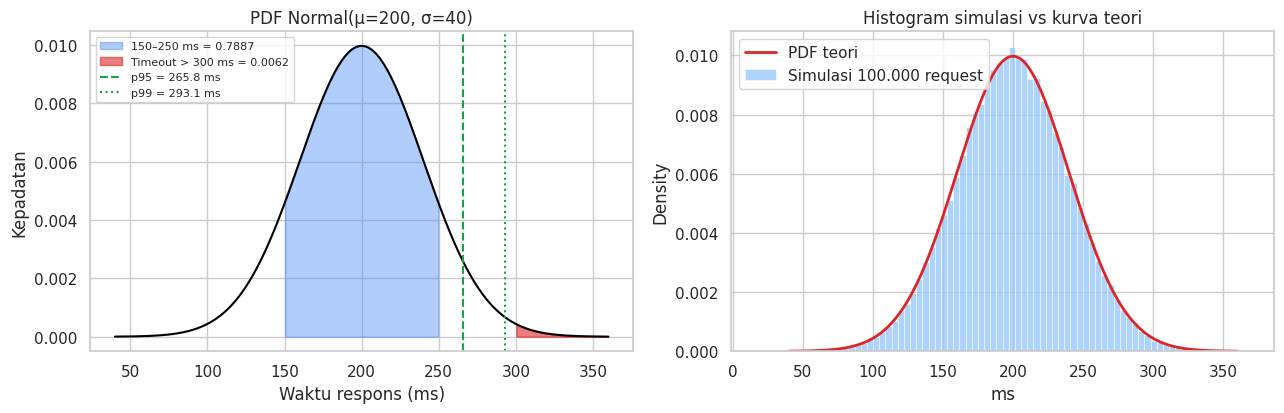

In [22]:
# f. Simulasi 100.000 request
sim = X.rvs(size=100_000, random_state=rng)
print("Aturan 68–95–99.7")
for kσ, teori in [(1, 0.6827), (2, 0.9545), (3, 0.9973)]:
    print(f"  μ ± {kσ}σ ({mu - kσ*sigma}–{mu + kσ*sigma} ms): simulasi = {(np.abs(sim - mu) <= kσ*sigma).mean():.4f} | teori = {teori}")
print(f"Timeout simulasi = {(sim > 300).mean():.4f} | teori = {X.sf(300):.4f}")

mu_hat, sigma_hat = norm.fit(sim)
print(f"norm.fit -> μ̂ = {mu_hat:.2f} ms, σ̂ = {sigma_hat:.2f} ms")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
xs = np.linspace(40, 360, 500)
ax[0].plot(xs, X.pdf(xs), color="black")
ax[0].fill_between(xs, X.pdf(xs), where=(xs > 150) & (xs < 250), color="#3b82f6", alpha=.4, label=f"150–250 ms = {X.cdf(250)-X.cdf(150):.4f}")
ax[0].fill_between(xs, X.pdf(xs), where=xs > 300, color="#dc2626", alpha=.6, label=f"Timeout > 300 ms = {X.sf(300):.4f}")
for q, ls in [(0.95, "--"), (0.99, ":")]:
    ax[0].axvline(X.ppf(q), ls=ls, color="#16a34a", label=f"p{int(q*100)} = {X.ppf(q):.1f} ms")
ax[0].set(title="PDF Normal(μ=200, σ=40)", xlabel="Waktu respons (ms)", ylabel="Kepadatan"); ax[0].legend(fontsize=8)

sns.histplot(sim, bins=80, stat="density", color="#93c5fd", ax=ax[1], label="Simulasi 100.000 request")
ax[1].plot(xs, X.pdf(xs), color="#dc2626", lw=2, label="PDF teori")
ax[1].set(title="Histogram simulasi vs kurva teori", xlabel="ms"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Distribusi Eksponensial — Waktu Antar Login Pengguna

**Konsep:** jika kejadian datang mengikuti **proses Poisson** dengan laju λ, maka **waktu tunggu antar kejadian** T berdistribusi eksponensial.

f(t) = λe^(−λt)  P(T ≤ t) = 1 − e^(−λt)  E(T) = 1/λ  Var(T) = 1/λ²  Sifat **memoryless**: P(T > s + t | T > s) = P(T > t)

**Soal**
Portal akademik menerima login rata-rata **3 login per menit** (λ = 3/menit = 0.05/detik). T = waktu antar dua login berturut-turut (detik).

a. P(login berikutnya datang < 10 detik)

b. P(tidak ada login selama > 60 detik)

c. P(10 < T < 30 detik)

d. E(T), Var(T), σ, dan median

e. Simulasi 50.000 jeda login: cek sifat *memoryless* P(T > 40 | T > 20) = P(T > 20)

f. Hubungan dengan Poisson: hitung jumlah login per menit dari simulasi jeda, apakah rata-ratanya 3?

**Hitung manual** (rata-rata jeda = 1/λ = 20 detik)
- a. P(T < 10) = 1 − e^(−10/20) = 1 − e^(−0.5) = **0.3935**
- b. P(T > 60) = e^(−60/20) = e⁻³ = **0.0498**
- c. P(10 < T < 30) = e^(−0.5) − e^(−1.5) = 0.6065 − 0.2231 = **0.3834**
- d. E(T) = **20 detik**, Var = **400 detik²**, σ = **20 detik**, median = 20 · ln 2 = **13.86 detik**


In [23]:
lam_detik = 3 / 60
T = expon(scale=1 / lam_detik)

print("=== Peluang ===")
print(f"a. P(T < 10)      = cdf(10)          = {T.cdf(10):.4f}   manual = {1 - math.exp(-0.5):.4f}")
print(f"b. P(T > 60)      = sf(60)           = {T.sf(60):.4f}   manual = {math.exp(-3):.4f}")
print(f"c. P(10 < T < 30) = cdf(30)-cdf(10)  = {T.cdf(30) - T.cdf(10):.4f}")
print(f"d. E(T) = {T.mean():.0f} s | Var(T) = {T.var():.0f} s² | σ = {T.std():.0f} s | median = {T.median():.2f} s")
print(f"   Persentil 90 jeda login = ppf(0.9) = {T.ppf(0.9):.2f} detik")

=== Peluang ===
a. P(T < 10)      = cdf(10)          = 0.3935   manual = 0.3935
b. P(T > 60)      = sf(60)           = 0.0498   manual = 0.0498
c. P(10 < T < 30) = cdf(30)-cdf(10)  = 0.3834
d. E(T) = 20 s | Var(T) = 400 s² | σ = 20 s | median = 13.86 s
   Persentil 90 jeda login = ppf(0.9) = 46.05 detik


Mean simulasi = 20.00 s (teori 20) | Std = 19.93 s (teori 20)
Memoryless: P(T > 40 | T > 20) = 0.3681 | P(T > 20) teori = 0.3679

Jumlah login per menit: mean = 2.9996, var = 2.9585 (Poisson λ=3: mean = var = 3)


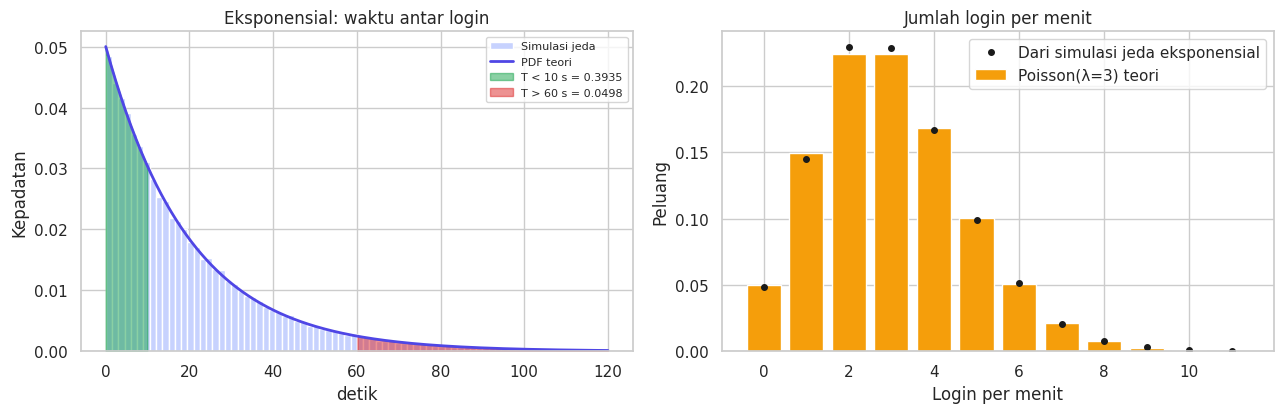

In [24]:
# e. Simulasi jeda login dengan numpy
jeda = rng.exponential(scale=1 / lam_detik, size=50_000)
print(f"Mean simulasi = {jeda.mean():.2f} s (teori 20) | Std = {jeda.std():.2f} s (teori 20)")
p_bersyarat = (jeda > 40).sum() / (jeda > 20).sum()
print(f"Memoryless: P(T > 40 | T > 20) = {p_bersyarat:.4f} | P(T > 20) teori = {T.sf(20):.4f}")

# f. Ubah jeda menjadi waktu kedatangan, lalu hitung jumlah login per menit
waktu_datang = np.cumsum(jeda)
menit = (waktu_datang // 60).astype(int)
per_menit = np.bincount(menit)[:-1]                      # buang menit terakhir yang belum lengkap
print(f"\nJumlah login per menit: mean = {per_menit.mean():.4f}, var = {per_menit.var():.4f} (Poisson λ=3: mean = var = 3)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ts = np.linspace(0, 120, 400)
ax[0].hist(jeda, bins=80, range=(0, 120), density=True, color="#c7d2fe", label="Simulasi jeda")
ax[0].plot(ts, T.pdf(ts), color="#4f46e5", lw=2, label="PDF teori")
ax[0].fill_between(ts, T.pdf(ts), where=ts < 10, color="#16a34a", alpha=.5, label=f"T < 10 s = {T.cdf(10):.4f}")
ax[0].fill_between(ts, T.pdf(ts), where=ts > 60, color="#dc2626", alpha=.5, label=f"T > 60 s = {T.sf(60):.4f}")
ax[0].set(title="Eksponensial: waktu antar login", xlabel="detik", ylabel="Kepadatan"); ax[0].legend(fontsize=8)

ks = np.arange(0, 12)
ax[1].bar(ks, poisson.pmf(ks, 3), color="#f59e0b", label="Poisson(λ=3) teori")
ax[1].plot(ks, [(per_menit == k).mean() for k in ks], "ko", ms=4, label="Dari simulasi jeda eksponensial")
ax[1].set(title="Jumlah login per menit", xlabel="Login per menit", ylabel="Peluang"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Distribusi t (Student) — Waktu Eksekusi Query Database

**Konsep:** dipakai saat menaksir/menguji **rata-rata populasi** dari **sampel kecil** dan **σ populasi tidak diketahui** (diganti simpangan baku sampel s).

t = (x̄ − μ₀) / (s/√n)  derajat bebas df = n − 1  E(t) = 0 (df > 1)  Var(t) = df/(df − 2) (df > 2)

Semakin besar df, distribusi t makin mendekati normal baku.

**Soal**
Tim backend mengklaim rata-rata waktu eksekusi query laporan **≤ 50 ms**. Setelah optimasi index, diambil **12 sampel** waktu eksekusi (ms):

52.1, 48.3, 55.7, 51.2, 49.8, 57.4, 53.6, 50.9, 54.2, 47.5, 56.3, 52.8

a. Hitung x̄, s, dan statistik t terhadap μ₀ = 50 ms

b. Uji hipotesis satu sisi H₀: μ ≤ 50 vs H₁: μ > 50, α = 0.05 (p-value dan t kritis)

c. Selang kepercayaan 95% untuk rata-rata waktu query

d. E(t) dan Var(t) untuk df = 11; bandingkan ekor distribusi t dengan normal

e. Simulasi: ambil 20.000 sampel berukuran 12 dari populasi normal, buktikan statistik t-nya mengikuti t(11)

**Hitung manual**
- x̄ = 629.8 / 12 = **52.4833 ms**
- s = √[Σ(xᵢ − x̄)² / (n − 1)] = √(107.2167/11) = **3.1220 ms** → SE = s/√12 = **0.9012**
- t = (52.4833 − 50) / 0.9012 = **2.755**
- t kritis (α = 0.05, df = 11, satu sisi) = **1.796** → t hitung > t kritis → **tolak H₀**
- CI 95%: 52.4833 ± 2.201 × 0.9012 = **(50.50 ; 54.47) ms**

In [25]:
data_query = np.array([52.1, 48.3, 55.7, 51.2, 49.8, 57.4, 53.6, 50.9, 54.2, 47.5, 56.3, 52.8])
mu0, alpha = 50, 0.05
n = len(data_query)
df = n - 1

xbar = data_query.mean()
s = data_query.std(ddof=1)
se = s / np.sqrt(n)
t_hitung = (xbar - mu0) / se

print("=== a. Statistik sampel ===")
print(f"n = {n}, df = {df}, x̄ = {xbar:.4f} ms, s = {s:.4f} ms, SE = {se:.4f}")
print(f"t hitung = {t_hitung:.4f}")

T = t(df)
t_kritis = T.ppf(1 - alpha)
p_value = T.sf(t_hitung)
print("\n=== b. Uji satu sisi (H1: μ > 50) ===")
print(f"t kritis = ppf(0.95) = {t_kritis:.4f}")
print(f"p-value  = sf(t)     = {p_value:.4f}")
uji = stats.ttest_1samp(data_query, popmean=mu0, alternative="greater")
print(f"Cek scipy ttest_1samp: t = {uji.statistic:.4f}, p-value = {uji.pvalue:.4f}")
print("Keputusan:", "Tolak H0" if p_value < alpha else "Gagal tolak H0")

print("\n=== c. Selang kepercayaan 95% ===")
t_ci = T.ppf(0.975)
print(f"t(0.975; 11) = {t_ci:.4f} -> CI = ({xbar - t_ci*se:.2f} ; {xbar + t_ci*se:.2f}) ms")
print(f"Cek t.interval: {tuple(round(v, 2) for v in t.interval(0.95, df, loc=xbar, scale=se))}")

print("\n=== d. Momen distribusi t(11) ===")
print(f"E(t) = {T.mean():.4f} | Var(t) = {T.var():.4f} (rumus df/(df-2) = {df/(df-2):.4f})")
print(f"P(|t| > 2.5): t(11) = {2*T.sf(2.5):.4f} | normal baku = {2*norm.sf(2.5):.4f}  -> ekor t lebih tebal")

=== a. Statistik sampel ===
n = 12, df = 11, x̄ = 52.4833 ms, s = 3.1220 ms, SE = 0.9012
t hitung = 2.7554

=== b. Uji satu sisi (H1: μ > 50) ===
t kritis = ppf(0.95) = 1.7959
p-value  = sf(t)     = 0.0094
Cek scipy ttest_1samp: t = 2.7554, p-value = 0.0094
Keputusan: Tolak H0

=== c. Selang kepercayaan 95% ===
t(0.975; 11) = 2.2010 -> CI = (50.50 ; 54.47) ms
Cek t.interval: (np.float64(50.5), np.float64(54.47))

=== d. Momen distribusi t(11) ===
E(t) = 0.0000 | Var(t) = 1.2222 (rumus df/(df-2) = 1.2222)
P(|t| > 2.5): t(11) = 0.0295 | normal baku = 0.0124  -> ekor t lebih tebal


Var statistik t simulasi = 1.1993 | teori t(11) = 1.2222 | normal = 1
Proporsi t > t kritis (kesalahan tipe I) = 0.0482 (seharusnya ≈ α = 0.05)


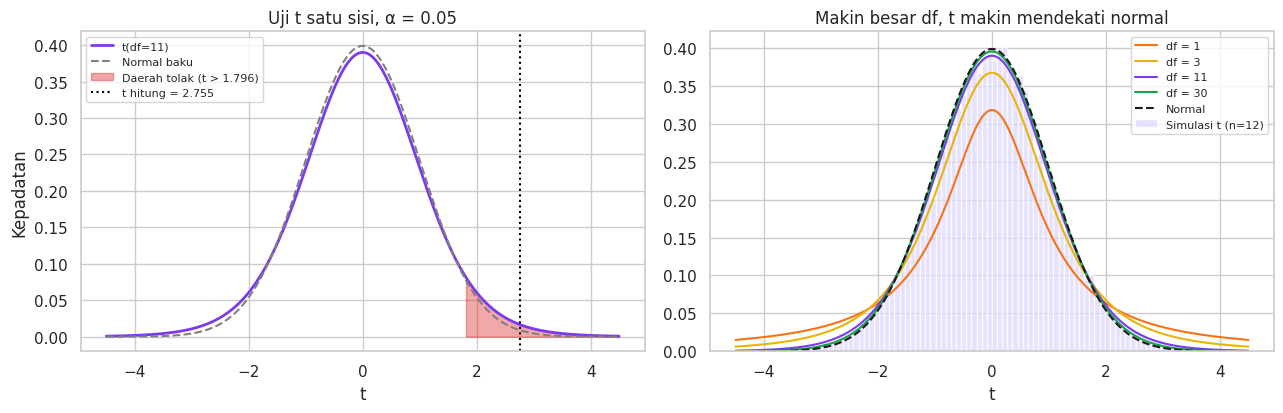

In [26]:
# e. Simulasi: populasi normal dengan μ = 50 (H0 benar), σ tidak diketahui
sampel = rng.normal(loc=50, scale=3, size=(20_000, n))
t_sim = (sampel.mean(axis=1) - 50) / (sampel.std(axis=1, ddof=1) / np.sqrt(n))
print(f"Var statistik t simulasi = {t_sim.var():.4f} | teori t(11) = {T.var():.4f} | normal = 1")
print(f"Proporsi t > t kritis (kesalahan tipe I) = {(t_sim > t_kritis).mean():.4f} (seharusnya ≈ α = 0.05)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
xs = np.linspace(-4.5, 4.5, 500)
ax[0].plot(xs, T.pdf(xs), color="#7c3aed", lw=2, label="t(df=11)")
ax[0].plot(xs, norm.pdf(xs), color="gray", ls="--", label="Normal baku")
ax[0].fill_between(xs, T.pdf(xs), where=xs > t_kritis, color="#dc2626", alpha=.4, label=f"Daerah tolak (t > {t_kritis:.3f})")
ax[0].axvline(t_hitung, color="black", ls=":", label=f"t hitung = {t_hitung:.3f}")
ax[0].set(title="Uji t satu sisi, α = 0.05", xlabel="t", ylabel="Kepadatan"); ax[0].legend(fontsize=8)

for d, c in [(1, "#f97316"), (3, "#eab308"), (11, "#7c3aed"), (30, "#16a34a")]:
    ax[1].plot(xs, t.pdf(xs, d), color=c, label=f"df = {d}")
ax[1].plot(xs, norm.pdf(xs), "k--", label="Normal")
ax[1].hist(t_sim, bins=100, range=(-4.5, 4.5), density=True, color="#ddd6fe", alpha=.7, label="Simulasi t (n=12)")
ax[1].set(title="Makin besar df, t makin mendekati normal", xlabel="t"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Distribusi F (ANOVA) — Membandingkan 3 Algoritma Sorting

**Konsep:** distribusi F adalah perbandingan dua varians. Pada **ANOVA satu arah**, F membandingkan variasi **antar kelompok** dengan variasi **di dalam kelompok** untuk menguji apakah rata-rata ≥ 3 kelompok sama.

F = MSB / MSW = [SSB/(k − 1)] / [SSW/(N − k)]  df₁ = k − 1, df₂ = N − k  E(F) = df₂/(df₂ − 2)

**Soal**
Mahasiswa mengukur waktu eksekusi (ms) **Quick Sort, Merge Sort, dan Heap Sort** untuk mengurutkan 100.000 data acak, masing-masing **6 kali percobaan**:

Quick Sort: 12.1, 11.8, 12.5, 11.6, 12.3, 12.0
Merge Sort: 13.4, 13.9, 13.1, 14.0, 13.6, 13.5
Heap Sort: 15.2, 14.8, 15.6, 15.0, 15.9, 14.9

a. Hitung rata-rata tiap algoritma dan tabel ANOVA (SSB, SSW, MSB, MSW, F) secara manual

b. Uji H₀: μ_quick = μ_merge = μ_heap pada α = 0.05 (F kritis dan p-value)

c. Verifikasi dengan scipy.stats.f_oneway dan statsmodels

d. Uji lanjut Tukey HSD: pasangan mana yang berbeda?

e. Simulasi distribusi F saat H₀ benar

**Hitung manual**
- Rata-rata: Quick = **12.05**, Merge = **13.583**, Heap = **15.233**, rata-rata total = **13.622**
- SSB = 6[(12.05 − 13.622)² + (13.583 − 13.622)² + (15.233 − 13.622)²] = **30.414**
- SSW = Σ(xᵢⱼ − x̄ⱼ)² = 0.535 + 0.548 + 0.933 = **2.017**
- df₁ = 3 − 1 = 2, df₂ = 18 − 3 = 15
- MSB = 30.414/2 = 15.207; MSW = 2.017/15 = 0.1344
- **F = 15.207 / 0.1344 = 113.1**, F kritis(0.05; 2; 15) = **3.68** → **tolak H₀**

In [27]:
data_sort = {
    "Quick": [12.1, 11.8, 12.5, 11.6, 12.3, 12.0],
    "Merge": [13.4, 13.9, 13.1, 14.0, 13.6, 13.5],
    "Heap":  [15.2, 14.8, 15.6, 15.0, 15.9, 14.9],
}
df_sort = pd.DataFrame([(alg, w) for alg, vals in data_sort.items() for w in vals], columns=["algoritma", "waktu"])

ringkas = df_sort.groupby("algoritma", sort=False)["waktu"].agg(["count", "mean", "var"])
print("Ringkasan per algoritma")
print(ringkas.round(4))

k = df_sort["algoritma"].nunique()
N = len(df_sort)
grand = df_sort["waktu"].mean()
SSB = sum(len(v) * (np.mean(v) - grand)**2 for v in data_sort.values())
SSW = sum(((np.array(v) - np.mean(v))**2).sum() for v in data_sort.values())
df1, df2 = k - 1, N - k
MSB, MSW = SSB / df1, SSW / df2
F_hitung = MSB / MSW

Fdist = f(df1, df2)
F_kritis = Fdist.ppf(0.95)
p_value = Fdist.sf(F_hitung)

print("\n=== a. Tabel ANOVA manual ===")
print(pd.DataFrame({
    "Sumber": ["Antar kelompok", "Dalam kelompok", "Total"],
    "SS": [SSB, SSW, SSB + SSW], "df": [df1, df2, N - 1],
    "MS": [MSB, MSW, np.nan], "F": [F_hitung, np.nan, np.nan],
}).round(4).to_string(index=False))

print(f"\n=== b. Uji F (α = 0.05) ===")
print(f"F kritis = f.ppf(0.95, {df1}, {df2}) = {F_kritis:.4f}")
print(f"p-value  = f.sf({F_hitung:.2f})       = {p_value:.2e}")
print("Keputusan:", "Tolak H0 -> minimal ada 1 algoritma yang rata-ratanya berbeda" if F_hitung > F_kritis else "Gagal tolak H0")
print(f"E(F) teori untuk df2 = 15 -> df2/(df2-2) = {Fdist.mean():.4f} | Var(F) = {Fdist.var():.4f}")

Ringkasan per algoritma
           count     mean     var
algoritma                        
Quick          6  12.0500  0.1070
Merge          6  13.5833  0.1097
Heap           6  15.2333  0.1867

=== a. Tabel ANOVA manual ===
        Sumber      SS  df      MS        F
Antar kelompok 30.4144   2 15.2072 113.1116
Dalam kelompok  2.0167  15  0.1344      NaN
         Total 32.4311  17     NaN      NaN

=== b. Uji F (α = 0.05) ===
F kritis = f.ppf(0.95, 2, 15) = 3.6823
p-value  = f.sf(113.11)       = 8.96e-10
Keputusan: Tolak H0 -> minimal ada 1 algoritma yang rata-ratanya berbeda
E(F) teori untuk df2 = 15 -> df2/(df2-2) = 1.1538 | Var(F) = 1.8155


In [28]:
# c. Verifikasi dengan scipy dan statsmodels
hasil = stats.f_oneway(*data_sort.values())
print(f"scipy f_oneway : F = {hasil.statistic:.4f}, p-value = {hasil.pvalue:.2e}")

model = ols("waktu ~ C(algoritma)", data=df_sort).fit()
print("\nstatsmodels anova_lm:")
print(sm.stats.anova_lm(model, typ=1).round(4))

# d. Uji lanjut Tukey HSD
print("\nTukey HSD:")
print(pairwise_tukeyhsd(df_sort["waktu"], df_sort["algoritma"], alpha=0.05))

scipy f_oneway : F = 113.1116, p-value = 8.96e-10

statsmodels anova_lm:
                df   sum_sq  mean_sq         F  PR(>F)
C(algoritma)   2.0  30.4144  15.2072  113.1116     0.0
Residual      15.0   2.0167   0.1344       NaN     NaN

Tukey HSD:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
  Heap  Merge    -1.65   0.0 -2.1999 -1.1001   True
  Heap  Quick  -3.1833   0.0 -3.7332 -2.6335   True
 Merge  Quick  -1.5333   0.0 -2.0832 -0.9835   True
---------------------------------------------------


Mean F simulasi = 1.1441 | teori E(F) = 1.1538
P(F > F kritis) simulasi = 0.0482 (seharusnya ≈ 0.05)
Nilai F terbesar dari 20.000 simulasi H0 = 19.15  vs  F data = 113.11


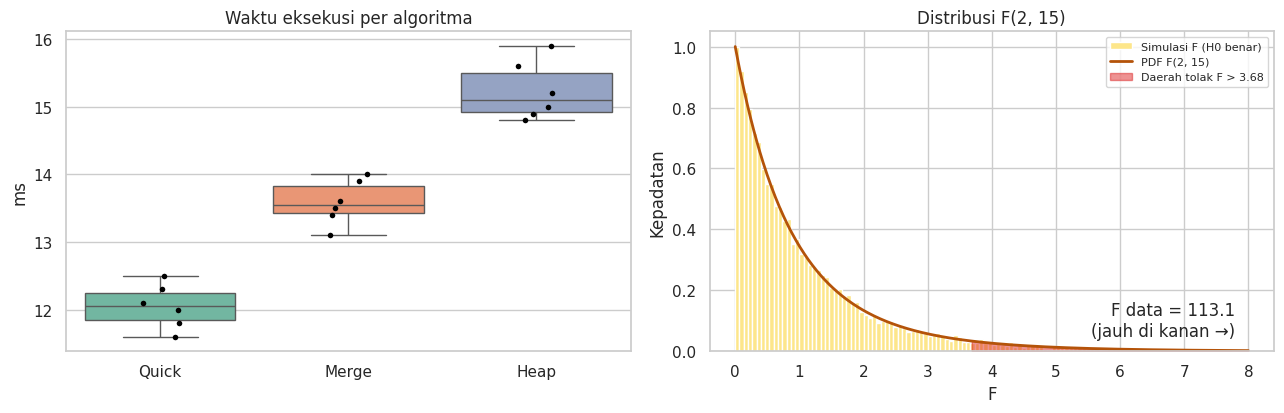

In [29]:
# e. Simulasi saat H0 benar: 3 kelompok dari populasi yang SAMA (μ = 13.6, σ = 0.36)
ulang = 20_000
F_sim = np.empty(ulang)
for i in range(ulang):
    g = rng.normal(13.6, 0.36, size=(3, 6))
    F_sim[i] = stats.f_oneway(*g).statistic
print(f"Mean F simulasi = {F_sim.mean():.4f} | teori E(F) = {Fdist.mean():.4f}")
print(f"P(F > F kritis) simulasi = {(F_sim > F_kritis).mean():.4f} (seharusnya ≈ 0.05)")
print(f"Nilai F terbesar dari 20.000 simulasi H0 = {F_sim.max():.2f}  vs  F data = {F_hitung:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
sns.boxplot(data=df_sort, x="algoritma", y="waktu", hue="algoritma", palette="Set2", legend=False, ax=ax[0])
sns.stripplot(data=df_sort, x="algoritma", y="waktu", color="black", size=4, ax=ax[0])
ax[0].set(title="Waktu eksekusi per algoritma", xlabel="", ylabel="ms")

xs = np.linspace(0, 8, 500)
ax[1].hist(F_sim, bins=120, range=(0, 8), density=True, color="#fde68a", label="Simulasi F (H0 benar)")
ax[1].plot(xs, Fdist.pdf(xs), color="#b45309", lw=2, label="PDF F(2, 15)")
ax[1].fill_between(xs, Fdist.pdf(xs), where=xs > F_kritis, color="#dc2626", alpha=.5, label=f"Daerah tolak F > {F_kritis:.2f}")
ax[1].annotate(f"F data = {F_hitung:.1f}\n(jauh di kanan →)", xy=(7.8, 0.05), ha="right")
ax[1].set(title="Distribusi F(2, 15)", xlabel="F", ylabel="Kepadatan"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()